# Projet Open Food Facts : Analyse, Nettoyage et Équilibrage du Dataset

Ce projet s'appuie sur un jeu de données extrait de la base globale publique **Open Food Facts**.

### Origine du Dataset
Le dataset utilisé provient de la plateforme **Kaggle** et est accessible via le lien suivant :
[Food Detailed Nutritional Content on Kaggle](https://www.kaggle.com/datasets/alexandrelemercier/food-detailed-nutritional-content?select=openfoodfacts_cleaned.csv)

#### Description officielle (Kaggle) :
> *"Ce jeu de données Open Food Facts est une collection exhaustive dérivée de la base de données Open Food Facts originale. Cette version allégée conserve les informations essentielles tout en réduisant sa taille de 9 Go à 400 Mo. Elle comprend des données sur environ 2 millions de produits alimentaires du monde entier (principalement de France et des États-Unis). Ce jeu de données est une excellente ressource pour quiconque souhaite mieux comprendre l'impact nutritionnel et environnemental d'une grande variété de produits alimentaires. Il peut contribuer à faire de meilleurs choix alimentaires et à adopter des habitudes alimentaires plus saines. En particulier, 11 des caractéristiques les plus utiles ne contiennent aucune valeur manquante."*

---

### Dictionnaire des Colonnes et Signification :
*   `product_name` : Le nom du produit.
*   `generic_name` : Nom général ou description du produit.
*   `quantity` : La quantité du produit dans son emballage (ex. « 500 g », « 1 L »).
*   `brands` : La ou les marques qui produisent le produit.
*   `categories_en` : Catégories auxquelles appartient le produit, en anglais.
*   `origins_en` : Pays d'origine des ingrédients, en anglais.
*   `countries_en` : Pays où le produit est vendu, en anglais.
*   `traces_en` : Traces potentielles d'allergènes (ex. : « traces d'arachides »).
*   `additives_n` : Nombre d'additifs présents dans le produit.
*   `additives_en` : Liste des additifs présents dans le produit, en anglais.
*   `nutriscore_score` : Le Nutri-Score du produit (note allant de -15 à +40).
*   `food_groups_en` : Classification des groupes alimentaires, en anglais.
*   `ecoscore_score` : L'éco-score du produit, qui mesure son impact environnemental.
*   `ecoscore_grade` : La note Eco-Score (de A à E) indiquant l'impact environnemental.
*   `main_category_en` : La catégorie principale du produit, en anglais.
*   `energy-kcal_100g` : Teneur en énergie en kilocalories pour 100 grammes.
*   `fat_100g` : Teneur totale en matières grasses pour 100 grammes.
*   `saturated-fat_100g` : Teneur en graisses saturées pour 100 grammes.
*   `monounsaturated-fat_100g` : Teneur en graisses mono-insaturées pour 100 grammes.
*   `polyunsaturated-fat_100g` : Teneur en graisses polyinsaturées pour 100 grammes.
*   `trans-fat_100g` : Teneur en gras trans pour 100 grammes.
*   `cholesterol_100g` : Teneur en cholestérol pour 100 grammes.
*   `carbohydrates_100g` : Teneur totale en glucides pour 100 grammes.
*   `sugars_100g` : Teneur en sucre pour 100 grammes.
*   `fiber_100g` : Teneur en fibres pour 100 grammes.
*   `proteins_100g` : Teneur en protéines pour 100 grammes.
*   `salt_100g` : Teneur en sel pour 100 grammes.
*   `sodium_100g` : Teneur en sodium pour 100 grammes.
*   `vitamin-a_100g` : Teneur en vitamine A pour 100 grammes.
*   `vitamin-d_100g` : Teneur en vitamine D pour 100 grammes.
*   `vitamin-c_100g` : Teneur en vitamine C pour 100 grammes.
*   `potassium_100g` : Teneur en potassium pour 100 grammes.
*   `calcium_100g` : Teneur en calcium pour 100 grammes.
*   `iron_100g` : Teneur en fer pour 100 grammes.
*   `fruits-vegetables-nuts-estimate-from-ingredients_100g` : Estimation de la teneur en fruits, légumes et noix pour 100g.
*   `nutrition-score-fr_100g` : Le Nutri-Score français brut pour 100 grammes, indiquant la qualité nutritionnelle globale.

---

## Étape 1 : Chargement des Données
Nous commençons par importer le dataset afin de faire un premier inventaire de sa taille et de ses types de colonnes.

In [145]:
import pandas as pd

# 1. Chargement du fichier CSV
file_path = './openfoodfacts_cleaned.csv'
df = pd.read_csv(file_path)

df = df.drop(columns=['Unnamed: 0']) # Index résiduel du au chargement initial du fichier

# Affichage des premières lignes
print("--- Aperçu des 5 premières lignes ---")
display(df.head())


--- Aperçu des 5 premières lignes ---


,product_name,generic_name,quantity,brands,categories_en,origins_en,countries_en,traces_en,additives_n,additives_en,...,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,potassium_100g,calcium_100g,iron_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g
0,Skyr,NaN,480 g,Danone,"Dairies,Fermented foods,Fermented milk product...",NaN,France,NaN,NaN,NaN,...,10.0,0.09,0.036,NaN,NaN,NaN,NaN,NaN,NaN,-5.0
1,Vitória crackers,NaN,NaN,NaN,NaN,NaN,France,NaN,NaN,NaN,...,7.8,1.40,0.560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Hamburguesas de ternera 100%,NaN,NaN,NaN,NaN,NaN,Spain,NaN,NaN,NaN,...,15.7,2.10,0.840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Blueberry Cobbler Coffee,NaN,NaN,NaN,NaN,NaN,United States,NaN,NaN,NaN,...,0.0,0.00,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Sauce Sweety chili 0%,NaN,NaN,NaN,NaN,NaN,France,NaN,NaN,NaN,...,0.2,2.04,0.816,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Pour de l'**apprentissage supervisé**, non devons choisir le label de nos données. Pour nous, ce sera les catégories de Nutri-Score A,B,C,d et E qu'on calcule à partir des valeurs de Nutri-Scores. Or, le jeu de données possède 2 features définies comme le Nutri-Score: **'nutriscore_score'** et **'nutrition-score-fr_100g'**. La différence n'étant pas évidente, on commence par comparer ces deux features.

In [ ]:
cols_to_compare = ['nutriscore_score', 'nutrition-score-fr_100g']

print("\n--- Taux de valeurs manquantes (NaN) ---")
print(df[['nutriscore_score', 'nutrition-score-fr_100g']].isna().sum())

# On filtre les lignes où au moins l'une des deux est renseignée (car 2 NaN sont comptés différents)
df_compare = df[df['nutriscore_score'].notna() | df['nutrition-score-fr_100g'].notna()]

# Différence stricte entre les deux colonnes (en excluant les NaN)
diff_mask = df_compare['nutriscore_score'] != df_compare['nutrition-score-fr_100g']
diff_count = diff_mask.sum()

print(f"\nNombre de lignes où les valeurs diffèrent (hors NaN) : {diff_count}")

if diff_count > 0:
    print("\nExemples de différences :")
    display(df_compare[diff_mask][cols_to_compare].head())
else:
    print("\nLes deux colonnes sont identiques sur tous le dataset. Colonne `nutriscore_score` supprimée !")
    # Suppression de la colonne "nutriscore_score"
    df = df.drop(columns="nutriscore_score")



--- Taux de valeurs manquantes (NaN) ---
nutriscore_score           963857
nutrition-score-fr_100g    963857
dtype: int64

Nombre de lignes où les valeurs diffèrent (hors NaN) : 0

Les deux colonnes sont identiques sur tous le dataset. On supprime donc l'une d'entre elles.


Nous allons maintenant manipuler certaines valeurs absurdes. Tout d'abord, certaines lignes possèdent plus de 100g de nutriments pour 100g de ce produit consommés. Nous supprimons ces lignes non pas pour toutes les features mais seulement pour celles que nous allons garder pour l'entraînement de notre modèle car ces erreurs absurdes issues de simples fautes de frappe n'influent pas les autres données du produit. Ainsi, on ne voudrait pas perdre une donnée précieuse d'entraînement car elle présente une unique valeur incohérente pour une feature qu'on supprime pendant le preprocessing.

In [147]:
import numpy as np

# Cap nutrients at 100g because values are given per 100g of the food product
mask_unconsistent_values = (
    (df['fat_100g'] > 100) | 
    (df['saturated-fat_100g'] > 100) | 
    (df['carbohydrates_100g'] > 100) | 
    (df['sugars_100g'] > 100) | 
    (df['fiber_100g'] > 100) | 
    (df['proteins_100g'] > 100) | 
    (df['salt_100g'] > 100) | 
    (df['fruits-vegetables-nuts-estimate-from-ingredients_100g'] > 100)
)

nb_valeurs_absurdes = len(df[mask_unconsistent_values])
df = df[~mask_unconsistent_values]
print(f"Nombre de lignes supprimées : {nb_valeurs_absurdes}")

# Correction des valeurs incohérentes pour les carbohydrates
df['carbohydrates_100g'] = np.maximum(df['carbohydrates_100g'], df['sugars_100g'])


Nombre de lignes supprimées : 2617


## Étape 2 : Filtrage Géographique (Focus sur la France)
L'objectif est d'étudier le marché de consommation français. Nous filtrons donc le dataset pour ne retenir que les produits vendus en France (`countries_en == 'France'`). Cela réduit le volume de données et améliore la pertinence de l'étude locale.

In [148]:
# 2. Filtrage pour l'arrivage / vente en France uniquement
df_france = df[df['countries_en'] == 'France']
print(f"Filtrage effectué sur la colonne 'countries_en' pour la valeur 'France'")

print(f"Nombre de lignes après filtrage : {df_france.shape[0]}")

Filtrage effectué sur la colonne 'countries_en' pour la valeur 'France'
Nombre de lignes après filtrage : 641545


## Étape 3 : Filtrage et Analyse Fondamentale des Notes Nutritionnelles

Dans cette étape, nous commençons par filtrer les données sans Nutri-Score car nous ne pourrons pas les utiliser pour l'entraînement. Ensuite, nous allons calculer la distribution des variables cibles d'impact de notre étude. Nous récupérons la valeur brute du Nutri-Score (feature **'nutrition-score-fr_100g'** allant de **-15** à **+40**) pour la classer en **5 catégories de A à E**.

Cette classification respecte la règle officielle du Nutri-Score en France :
*   **Catégorie A** : Si le score est compris entre **-15 et -1** inclus.
*   **Catégorie B** : Si le score est compris entre **0 et 2** inclus.
*   **Catégorie C** : Si le score est compris entre **3 et 10** inclus.
*   **Catégorie D** : Si le score est compris entre **11 et 18** inclus.
*   **Catégorie E** : Si le score est compris entre **19 et 40** inclus.

Nous analysons ensuite la distribution et le pourcentage de chaque score et catégorie sur notre jeu de données.

In [149]:
# ==========================================
# 1. ANALYSE DU NUTRI-SCORE (VALEURS DE -15 À +40)
# ==========================================

nutri_col = 'nutrition-score-fr_100g' #

# Filtrage des lignes non labelisées (= sans Nutri-Score renseigné)
df_france_nutri_valide = df_france[df_france[nutri_col].notna()]
print("Nombre de lignes du dataset après filtrage des produits non labelisés:", df_france_nutri_valide.shape[0])

# Pour chaque valeur unique de score (de -15 à 40), on compte le nombre de produits (lignes)
score_counts = df_france_nutri_valide[nutri_col].value_counts().sort_index()

# Nous calculons ensuite la proportion que représente chaque score sur le total
# On multiplie par 100 pour obtenir des valeurs en %
score_pcts = (df_france_nutri_valide[nutri_col].value_counts(normalize=True) * 100).sort_index()

# Création d'un tableau synthétique pour afficher les effectifs et les pourcentages par valeur de score
df_detailed_scores = pd.DataFrame({
    'Nombre de lignes': score_counts,
    'Pourcentage (%)': score_pcts.round(2)
})

print("--- Répartition détaillée du score nutritionnel (-15 à +40) ---")
display(df_detailed_scores)

# ==========================================
# 2. REGROUPEMENT DU NUTRI-SCORE EN 5 CATÉGORIES (A, B, C, D, E)
# ==========================================

# Définition de la fonction de classification selon les tranches demandées
def attribuer_categorie(score):
    if -15 <= score <= -1:
        return 'A'
    elif 0 <= score <= 2:
        return 'B'
    elif 3 <= score <= 10:
        return 'C'
    elif 11 <= score <= 18:
        return 'D'
    elif 19 <= score <= 40:
        return 'E'
    return np.nan

# Application de la fonction pour créer une nouvelle colonne contenant la catégorie A, B, C, D ou E
df_france_nutri_valide['nutriscore_categorie'] = df_france_nutri_valide[nutri_col].apply(attribuer_categorie)

# Comptage des effectifs et des pourcentages pour chaque catégorie créée (même méthode qu'au-dessus)
cat_counts = df_france_nutri_valide['nutriscore_categorie'].value_counts().sort_index()
cat_pcts = (df_france_nutri_valide['nutriscore_categorie'].value_counts(normalize=True) * 100).sort_index()

# Assemblage des résultats dans un tableau récapitulatif pour le Nutri-Score
df_nutri_categories = pd.DataFrame({
    'Nombre de lignes': cat_counts,
    'Pourcentage (%)': cat_pcts.round(2)
})

print("\n--- Tableau récapitulatif par catégorie Nutri-Score (A à E) ---")
display(df_nutri_categories)

Nombre de lignes du dataset après filtrage des produits non labelisés: 323803
--- Répartition détaillée du score nutritionnel (-15 à +40) ---


,Nombre de lignes,Pourcentage (%)
nutrition-score-fr_100g,,
-15.0,2,0.00
-14.0,19,0.01
-13.0,54,0.02
-12.0,216,0.07
-11.0,380,0.12
-10.0,369,0.11
-9.0,486,0.15
-8.0,717,0.22
-7.0,1044,0.32



--- Tableau récapitulatif par catégorie Nutri-Score (A à E) ---


,Nombre de lignes,Pourcentage (%)
nutriscore_categorie,,
A,46641,14.40
B,44215,13.65
C,71389,22.05
D,105941,32.72
E,55617,17.18


Après cette étape, le dataset possède maintenant **324 624 lignes**, et tous les produits sont labelisés. La catégorie de Nutri-Score avec le moins d'éléments est la **B avec 44 316 produits**, un nombre suffisamment grand pour que notre étude statistique soit pertinente, donc nous pouvons valider cette répartition des Nutri-Scores en 5 catégories.



## Étape 4 : Analyse des Valeurs Manquantes Post-Filtrage
Maintenant que nous nous concentrons uniquement sur la **France et sur les produits ayant un Nutri-Score renseigné**, nous réévaluons le taux de données manquantes (NaN) par colonne.

In [150]:
print("--- Nombre de valeurs manquantes (NaN) par colonne pour le jeu de données France avec Nutri-Score renseigné ---")
print(f"Taille du sous-ensemble : {df_france_nutri_valide.shape[0]} lignes\n")

# Calcul du nombre de NaN
nan_counts_sub = df_france_nutri_valide.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_france_nutri_valide.isna().sum() / len(df_france_nutri_valide)) * 100).round(2)

display(nan_counts_sub)


--- Nombre de valeurs manquantes (NaN) par colonne pour le jeu de données France avec Nutri-Score renseigné ---
Taille du sous-ensemble : 323803 lignes



,Nombre de NaN,Pourcentage (%)
product_name,0,0.00
generic_name,272546,84.17
quantity,153686,47.46
brands,82986,25.63
categories_en,0,0.00
origins_en,287048,88.65
countries_en,0,0.00
traces_en,268266,82.85
additives_n,158890,49.07
additives_en,235824,72.83


De nombreuses features possèdent près de 100% de valeurs non définies. Nous devons donc maintenant trier les features de notre jeu de données pour optimiser l'entraînement de notre modèle.

## Étape 5 : Nettoyage Dimensionnel et Suppression de Colonnes
A cette étape, nous décidons de supprimer un ensemble de colonnes afin d'optimiser le modèle. Différentes raisons justifient nos choix, dont voici le détail:

#### 1. Taux de NaN critique > 98-99%:
*   `vitamin-a_100g`, `vitamin-c_100g`, `potassium_100g`, `calcium_100g`, `iron_100g`: Ces variables présentent un taux de valeurs manquantes (NaN) extrêmement élevé sur le marché français, ce qui les rend inexploitables pour notre entraînement statistique.

#### 2. Informations textuelles secondaires, catégorielles lourdes ou redondantes
*   `generic_name` : Description textuelle trop variée, générique et redondante avec `product_name` ou les catégories.
*   `quantity` : Contient des formats de texte non normalisés (ex. "500g", "1 L") sans impact direct sur la qualité nutritionnelle.
*   `brands` : Donnée catégorielle à très haute cardinalité (des milliers de marques différentes), ce qui complexifierait inutilement les modèles de prédiction sans valeur ajoutée nutritionnelle directe.
*   `origins_en` : Pays d'origine des ingrédients. Très majoritairement non renseigné (88.64%) et textuel.
*   `traces_en` : Traces potentielles d'allergènes. Informations textuelles très incomplètes (82.62%) et non structurées.
*   `additives_en`,`additifs_n`: Les additifs présents dans un produit alimentaire n'ont aucun lien avec le calcul du Nutri-Score et peuvent même être trompeuses car certains produits contenants de nombreux additifs peuvent avoir un très bon Nutri-Score s'ils sont peu caloriques, ne contiennent que très peu de sucre... On empêche ainsi notre modèle de s'égarer.

#### 3. Détails de graisses secondaires ou spécifiques
*   `monounsaturated-fat_100g`, `polyunsaturated-fat_100g`, `trans-fat_100g` : Sous-catégories de lipides qui sont très peu renseignées, contrairement à la colonne globale `fat_100g` (matières grasses totales) et `saturated-fat_100g` (graisses saturées) que nous conservons.
*   `cholesterol_100g` : Taux de cholestérol, colonne quasiment vide en Europe car son affichage n'est pas obligatoire sur les étiquetages nutritionnels français (contrairement aux USA).

#### 4. Variables redondantes (Colinéarité parfaite)
*   `sodium_100g` : Le sel alimentaire (NaCl) est constitué à 40% de sodium et 60% de chlore d'où la relation `salt_100g` = 2.5 * `sodium_100g`. On peut  donc supprimer cette feature, qui ne contient aucune information supplémentaire.

#### 5. Indicateurs environnementaux hors sujet
*   `ecoscore_score`, `ecoscore_grade` : L'Éco-Score mesure l'impact environnemental du produit ce qui n'a aucun impact sur l'aspect nutritionnel (Nutri-Score) et peut même ajouter du bruit et détériorer le modèle. De plus, cet éco-score n'est pas renseigné pour un gros pourcentage de nos données.

#### 6. Variables catégorielles trop spécifiques et complexes à analyser (voir code cellule suivante)
* `categories_en`, `main_category_en`, `categories_en`, : Respectivement 42 380, 15 382 et 210 148 valeurs différentes, trop spécifiques pour la grande majorité des éléments. On pourrait garder seulement les catégories les plus importantes et regrouper les autres dans une catégorie 'autre' mais cette dernière serait, ici, trop importante.

#### 7. Pays de vente 
* `countries_en` : A cette étape, tous les éléments présents possèdent la même valeur: France



In [151]:
df_france_nutri_valide[df_france_nutri_valide['generic_name'] == 'Pâtes alimentaires de qualité supérieure'][['generic_name','product_name']]


,generic_name,product_name
736139,Pâtes alimentaires de qualité supérieure,Vermicelles
782863,Pâtes alimentaires de qualité supérieure,Panzani etoiles 500g
782864,Pâtes alimentaires de qualité supérieure,Panzani alphabets 500g
782866,Pâtes alimentaires de qualité supérieure,Panzani pescadines
782867,Pâtes alimentaires de qualité supérieure,cheveux d'ange
...,...,...
1716576,Pâtes alimentaires de qualité supérieure,Fusilloni Al bronzo
1716599,Pâtes alimentaires de qualité supérieure,Barilla piccolini mini tortiglioni 500g
1716618,Pâtes alimentaires de qualité supérieure,Spaghetti quad 400g albronzo fr
1716630,Pâtes alimentaires de qualité supérieure,Barilla pates fusilli 500g+200g offert


In [152]:
print(f"Nombre de Produits dans 'product_name' : {len(df_france_nutri_valide['product_name'].value_counts())}")
print(f"Nombre de Noms de Produits dans 'generic_name' : {len(df_france_nutri_valide['generic_name'].value_counts())} \n")

print(f"Nombre de Marques dans 'brands' : {len(df_france_nutri_valide['brands'].value_counts())}")
print(f"Nombre de Additifs dans 'additives_en' : {len(df_france_nutri_valide['additives_en'].value_counts())} \n")

print(f"Nombre de Catégories dans 'categories_en' : {len(df_france_nutri_valide['categories_en'].value_counts())}")
print(f"Nombre de Catégories principales dans 'main_category_en' : {len(df_france_nutri_valide['main_category_en'].value_counts())}")


Nombre de Produits dans 'product_name' : 209513
Nombre de Noms de Produits dans 'generic_name' : 37767 

Nombre de Marques dans 'brands' : 44965
Nombre de Additifs dans 'additives_en' : 22336 

Nombre de Catégories dans 'categories_en' : 42649
Nombre de Catégories principales dans 'main_category_en' : 15339


In [153]:
# Liste des colonnes à supprimer
columns_to_drop = [
     'generic_name', 'quantity', 'brands', 'origins_en', 'traces_en', 'additives_en', 'additives_n',
     'monounsaturated-fat_100g', 'polyunsaturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g',
     'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g', 'iron_100g',
     'sodium_100g',
     'ecoscore_score','ecoscore_grade',
     'categories_en', 'main_category_en','product_name'
     ,'countries_en'
]

# Sécurité (contre fautes de frappe par exemple): on vérifie que toutes les colonnes à supprimer existent dans le df
missing_cols = [col for col in columns_to_drop if col not in df_france_nutri_valide.columns]

if missing_cols:
    raise ValueError(f"Erreur : Les colonnes suivantes sont absentes du dataset et ne peuvent pas être supprimées : {missing_cols}")

# Suppression des colonnes
df_france_final = df_france_nutri_valide.drop(columns=columns_to_drop)

# Affichage des dimensions du nouveau dataset
print("--- Dimensions du nouveau jeu de données final ---")
print(f"Nombre de lignes : {df_france_final.shape[0]}")
print(f"Nombre de colonnes : {df_france_final.shape[1]}\n")

# Calcul et affichage du nombre et pourcentage de NaN pour les colonnes restantes
nan_counts_final = df_france_final.isna().sum().to_frame(name='Nombre de NaN')
nan_counts_final['Pourcentage (%)'] = ((df_france_final.isna().sum() / len(df_france_final)) * 100).round(2)

print("--- Valeurs manquantes (NaN) par colonne restante ---")
display(nan_counts_final)



--- Dimensions du nouveau jeu de données final ---
Nombre de lignes : 323803
Nombre de colonnes : 12

--- Valeurs manquantes (NaN) par colonne restante ---


,Nombre de NaN,Pourcentage (%)
food_groups_en,30697,9.48
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,201143,62.12
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,159055,49.12


## Étape 6 : Échantillonnage intelligent et Équilibrage du Dataset
Un grand problème en Machine Learning est le déséquilibre des classes (par exemple, beaucoup plus de produits de classe D que de classe B).
Pour y remédier, nous développons un algorithme d'échantillonnage stratifié qui :
1. Trie les produits de chaque catégorie pour privilégier ceux contenant **le moins de valeurs manquantes** (la meilleure qualité possible).
2. Prélève une taille cible identique pour chaque classe Nutri-Score afin d'assurer un équilibre parfait.

In [154]:
# =====================================================================
# ÉQUILIBRAGE DU JEU DE DONNÉES EN PRIVILÉGIANT LES LIGNES SANS NAN
# =====================================================================

# 1. Calcul du nombre de NaN pour chaque ligne (axe 1)
df_france_final = df_france_final.copy()
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

# Création de la colonne de catégorie Nutri-Score sur ce dataset final
df_france_final['nutriscore_categorie'] = df_france_final['nutrition-score-fr_100g'].apply(attribuer_categorie)

# 2. Détermination de la taille cible pour l'équilibrage
# On regarde la taille actuelle de chaque catégorie
counts_by_cat = df_france_final['nutriscore_categorie'].value_counts()
print("Nombre de lignes initial par catégorie :")
print(counts_by_cat)

# La taille cible sera dictée par la plus petite catégorie pour garantir une proportion équivalente (1:1:1:1:1).
min_cat_size = counts_by_cat.min()

# Ajustement de la taille cible selon les limites demandées (entre 10 000 et 400 000 lignes par classe)
target_size = max(10000, min(400000, min_cat_size))
print(f"\nTaille cible choisie par catégorie : {target_size} lignes (Total pour le dataset : {target_size * 5} lignes)\n")

# 3. Échantillonnage stratifié en éliminant en priorité les lignes avec le plus de NaN
balanced_chunks = []

for cat in ['A', 'B', 'C', 'D', 'E']:
    # Isolation de la catégorie courante
    df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]

    # Tri des lignes : celles ayant le moins de NaN en premier
    df_cat_sorted = df_cat.sort_values(by='nb_nan_ligne', ascending=True)

    # Sélection des 'target_size' premières lignes (les plus complètes)
    df_cat_sampled = df_cat_sorted.head(target_size)

    # Ajout à notre liste de blocs
    balanced_chunks.append(df_cat_sampled)

# Fusion des blocs échantillonnés pour obtenir le dataset équilibré
df_balanced = pd.concat(balanced_chunks).sort_index()

# Nettoyage de la colonne temporaire de calcul des NaN par ligne
df_balanced = df_balanced.drop(columns=['nb_nan_ligne'])

# 4. Vérification et affichage du résultat final
print("--- Validation du nouveau jeu de données équilibré ---")
print(f"Nombre total de lignes : {df_balanced.shape[0]}")
print(f"Nombre de colonnes : {df_balanced.shape[1]}\n")

print("Distribution finale des catégories :")
display(df_balanced['nutriscore_categorie'].value_counts().to_frame(name='Nombre de lignes'))

Nombre de lignes initial par catégorie :
nutriscore_categorie
D    105941
C     71389
E     55617
A     46641
B     44215
Name: count, dtype: int64

Taille cible choisie par catégorie : 44215 lignes (Total pour le dataset : 221075 lignes)

--- Validation du nouveau jeu de données équilibré ---
Nombre total de lignes : 221075
Nombre de colonnes : 12

Distribution finale des catégories :


,Nombre de lignes
nutriscore_categorie,
C,44215
A,44215
D,44215
B,44215
E,44215


## Étape 7 : Évaluation du Taux de NaN Post-Équilibrage

In [155]:
# Calcul du nombre et du pourcentage de valeurs manquantes (NaN) par colonne pour le jeu de données équilibré (df_balanced)
print("--- Valeurs manquantes (NaN) par colonne dans le sous-ensemble équilibré et optimisé ---")
print(f"Taille du dataset équilibré : {df_balanced.shape[0]} lignes\n")

nan_counts_balanced = df_balanced.isna().sum().to_frame(name='Nombre de NaN')
nan_counts_balanced['Pourcentage (%)'] = ((df_balanced.isna().sum() / len(df_balanced)) * 100).round(2)

display(nan_counts_balanced)

--- Valeurs manquantes (NaN) par colonne dans le sous-ensemble équilibré et optimisé ---
Taille du dataset équilibré : 221075 lignes



,Nombre de NaN,Pourcentage (%)
food_groups_en,14142,6.40
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,103352,46.75
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,67177,30.39


## Étape 8 : Choix du Compromis Optimal de Taille d'Échantillon
Nous menons une étude de sensibilité pour analyser comment le taux de valeurs manquantes se comporte selon la taille de l'échantillon choisie par catégorie. Plus on restreint l'échantillon aux meilleurs candidats, plus le taux de NaN chute vers 0 %.

In [157]:
import pandas as pd
import numpy as np

# Définition de nombre de lignes cible pour voir l'impact sur pourcentage de Nan
tailles_detaillees = [44316, 42500, 40000, 37500, 35000, 32500, 30000, 27500,
                      25000, 22500, 20000, 17500, 15000, 12500, 10000]

# Liste des colonnes spécifiques à analyser
colonnes_cibles = [
    'food_groups_en',
    'fiber_100g',
    'fruits-vegetables-nuts-estimate-from-ingredients_100g'
]

# Dictionnaire pour stocker les résultats pour chaque scénario
comparatif_scenarios = {}

# S'assurer que la colonne temporaire 'nb_nan_ligne' est bien présente
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

for taille in tailles_detaillees:
    balanced_chunks_temp = []
    for cat in ['A', 'B', 'C', 'D', 'E']:
        df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]
        # Sélection des lignes les plus complètes (tri croissant sur nb_nan_ligne)
        df_cat_sampled = df_cat.sort_values(by='nb_nan_ligne', ascending=True).head(taille)
        balanced_chunks_temp.append(df_cat_sampled)

    # Fusion du sous-ensemble temporaire pour cette taille
    df_temp = pd.concat(balanced_chunks_temp)

    # Calcul du % de NaN pour les colonnes cibles
    pct_nan_series = (df_temp[colonnes_cibles].isna().sum() / len(df_temp)) * 100

    # Stockage des résultats
    col_name = f"{taille}/cat (Total: {taille*5})"
    comparatif_scenarios[col_name] = pct_nan_series.round(2)

# Transformation en DataFrame pour une meilleure lisibilité
df_comparatif_detaille = pd.DataFrame(comparatif_scenarios)

print("--- POURCENTAGE DE NaN PAR COLONNE SELON LE NOMBRE DE LIGNES PAR CATÉGORIE ---")
display(df_comparatif_detaille)

--- POURCENTAGE DE NaN PAR COLONNE SELON LE NOMBRE DE LIGNES PAR CATÉGORIE ---


,44316/cat (Total: 221580),42500/cat (Total: 212500),40000/cat (Total: 200000),37500/cat (Total: 187500),35000/cat (Total: 175000),32500/cat (Total: 162500),30000/cat (Total: 150000),27500/cat (Total: 137500),25000/cat (Total: 125000),22500/cat (Total: 112500),20000/cat (Total: 100000),17500/cat (Total: 87500),15000/cat (Total: 75000),12500/cat (Total: 62500),10000/cat (Total: 50000)
food_groups_en,6.40,5.61,4.95,4.73,4.50,4.26,3.76,3.26,2.58,1.73,1.09,0.76,0.36,0.09,0.01
fiber_100g,46.82,44.97,42.36,39.57,36.27,32.69,29.22,25.11,21.56,17.11,11.91,9.44,6.65,3.64,0.26
fruits-vegetables-nuts-estimate-from-ingredients_100g,30.48,28.25,25.59,22.80,19.69,16.41,13.17,10.11,8.12,5.89,3.74,2.77,1.46,0.50,0.02


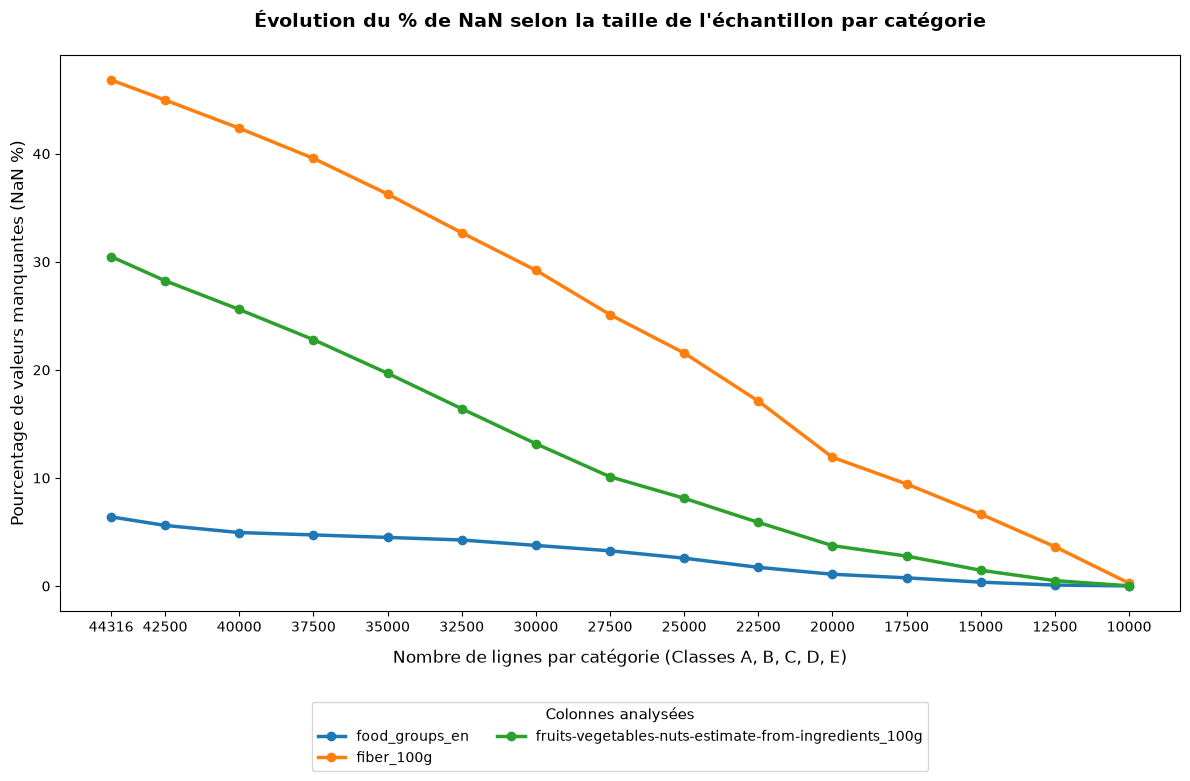

In [158]:
import matplotlib.pyplot as plt
# import seaborn as sns

# Configuration du style graphique
plt.figure(figsize=(12, 8))
# sns.set_theme(style="whitegrid")

# Inversion des colonnes pour avoir l'ordre croissant du nombre de lignes sur l'axe X
df_plot = df_comparatif_detaille.copy()
# On extrait uniquement le nombre de lignes par catégorie pour l'axe X (ex: '20000' depuis '20000/cat')
nb_lignes_categories = [int(col.split('/')[0]) for col in df_plot.columns]

# Tracer une courbe pour chaque colonne cible
for index, row in df_plot.iterrows():
    plt.plot(nb_lignes_categories, row.values, marker='o', linewidth=2.5, label=index)

# Personnalisation du graphique
plt.title("Évolution du % de NaN selon la taille de l'échantillon par catégorie", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Nombre de lignes par catégorie (Classes A, B, C, D, E)", fontsize=12, labelpad=10)
plt.ylabel("Pourcentage de valeurs manquantes (NaN %)", fontsize=12)
plt.xticks(nb_lignes_categories)
plt.gca().invert_xaxis()  # Garder la logique décroissante pour voir l'impact de la réduction

# Positionnement de la légende en dessous du graphique pour libérer de l'espace horizontal
plt.legend(
    title="Colonnes analysées",
    title_fontsize='11',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,          # Disposer la légende sur 2 colonnes pour la compacité
    frameon=True
)

# Ajustement automatique des marges pour éviter que la légende sous le graphique ne soit coupée
plt.tight_layout()

# Affichage
plt.show()

## Étape 9 : Sélection Finale et Exportation du Dataset (100 000 Lignes)
Sur la base de notre graphique d'analyse de compromis, nous sélectionnons **20 000 lignes par catégorie** (soit un jeu final de **100 000 lignes**). Ce choix offre un excellent compromis en termes de volume de données tout en garantissant des taux de valeurs manquantes (NaN) quasi-nuls pour nos colonnes clés comme les fibres.

In [159]:
# Sélection stricte et directe de 20 000 lignes par catégorie et sauvegarde
target_size_final = 20000
balanced_chunks_final = []

# Calcul temporaire pour trier par complétude
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

for cat in ['A', 'B', 'C', 'D', 'E']:
    df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]
    df_cat_sampled = df_cat.sort_values(by='nb_nan_ligne', ascending=True).head(target_size_final)
    balanced_chunks_final.append(df_cat_sampled)

# Création du dataset final et suppression de la colonne temporaire
df_balanced_100k = pd.concat(balanced_chunks_final).sort_index()
df_balanced_100k = df_balanced_100k.drop(columns=['nb_nan_ligne'])

# Sauvegarde sous format CSV pour téléchargement
output_path = 'openfoodfacts_balanced_100k.csv'
df_balanced_100k.to_csv(output_path, index=False)

print(f"Fichier sauvegardé avec succès : {output_path} ({df_balanced_100k.shape[0]} lignes)")

Fichier sauvegardé avec succès : openfoodfacts_balanced_100k.csv (100000 lignes)


## Étape 10 : Entraînement du modèle
Maintenant que les données ont été clean, nous pouvons maintenant passer à la construction de notre pipeline, c'est-à-dire la constuction de notre modèle.

In [160]:
import pandas as pd

file_path = './openfoodfacts_balanced_100k.csv'
df_cleaned = pd.read_csv(file_path)

In [161]:
df_cleaned.head()

,food_groups_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g,nutriscore_categorie
0,"Cereals and potatoes,Bread",160.0,2.2,0.5,25.2,0.6,1.6,9.5,0.358,0.000000,-4.0,A
1,"Fruits and vegetables,Fruits",377.0,0.5,0.1,93.0,66.0,NaN,1.5,0.020,76.000000,1.0,B
2,"Beverages,Unsweetened beverages",4.0,0.1,0.1,0.1,0.1,NaN,0.1,0.001,0.000000,2.0,B
3,"Cereals and potatoes,Cereals",240.0,1.6,0.3,47.0,0.2,NaN,8.3,1.140,0.358073,2.0,B
4,"Sugary snacks,Sweets",250.0,0.0,0.0,95.0,0.0,0.0,0.0,0.000,0.000000,3.0,C


In [162]:
nan_counts_sub = df_cleaned.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_cleaned.isna().sum() / len(df_cleaned)) * 100).round(2)

display(nan_counts_sub)

,Nombre de NaN,Pourcentage (%)
food_groups_en,1088,1.09
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,11913,11.91
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,3745,3.74


Pour la feature `food_groups_en`, on regroupe les 1088 NaN dans le groupe 'Unknown', déjà présents dans nos données.

In [164]:
df_cleaned[df_cleaned['food_groups_en'] == 'Unknown']

,food_groups_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g,nutriscore_categorie
821,Unknown,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,B
2453,Unknown,1.0,0.0,0.0,0.2,0.00,NaN,0.1,0.0,6.00,1.0,B
19490,Unknown,4.0,0.0,0.0,0.5,0.50,0.0,0.5,0.0,8.55,2.0,B
63994,Unknown,1.0,0.0,0.0,0.2,0.00,0.0,0.1,0.0,0.00,1.0,B
82190,Unknown,1.0,0.0,0.0,0.2,0.10,NaN,0.0,0.0,0.00,2.0,B
83820,Unknown,4.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,1.0,B
85348,Unknown,1.0,0.0,0.0,0.2,0.00,0.0,0.1,0.0,7.00,1.0,B
96998,Unknown,1.0,0.0,0.0,0.2,0.00,NaN,0.0,0.0,0.00,1.0,B
97233,Unknown,1.0,0.0,0.0,0.2,0.13,0.0,0.0,0.0,NaN,2.0,B
99494,Unknown,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,NaN,1.0,B


Pour la feature `fruits-vegetables-nuts-estimate-from-ingredients_100g`, on a 3 745 NaN. On impute avec la moyenne du food_groups_en pour les variances raisonnables et on supprime le reste.

In [ ]:
# Affichage des lignes NaN 
df_cleaned[df_cleaned['fruits-vegetables-nuts-estimate-from-ingredients_100g'].isna()]

,food_groups_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-nuts-estimate-from-ingredients_100g,nutrition-score-fr_100g,nutriscore_categorie
57,"Composite foods,Sandwiches",201.0,4.7,1.90,28.9,2.1,1.4,10.90,1.20,NaN,2.0,B
61,"Composite foods,Sandwiches",209.0,7.5,0.59,29.0,2.4,4.3,5.63,1.59,NaN,2.0,B
65,"Cereals and potatoes,Cereals",140.0,11.0,0.90,7.2,6.4,2.7,1.00,0.60,NaN,2.0,B
68,"Sugary snacks,Pastries",53.0,0.0,0.00,12.4,10.7,0.7,0.50,0.10,NaN,2.0,B
69,"Cereals and potatoes,Bread",277.0,5.0,0.50,48.0,6.5,5.4,7.40,1.50,NaN,1.0,B
...,...,...,...,...,...,...,...,...,...,...,...,...
99990,"Fats and sauces,Dressings and sauces",512.0,33.0,3.00,46.0,14.0,2.5,4.40,5.90,NaN,19.0,E
99991,"Fish‚ Meat‚ Eggs,Processed meat",110.0,2.0,0.80,0.9,0.5,0.5,22.00,1.30,NaN,1.0,B
99992,"Fish‚ Meat‚ Eggs,Meat,Poultry",203.0,10.0,2.00,14.0,0.9,0.7,14.00,0.99,NaN,2.0,B
99993,"Sugary snacks,Sweets",107.0,5.3,2.70,11.0,7.0,3.4,2.10,0.02,NaN,0.0,B


In [173]:
import pandas as pd

# Define your target column and the standard deviation threshold
col = 'fruits-vegetables-nuts-estimate-from-ingredients_100g'
std_threshold = 30.0  # Adjust this value based on your preference

# 1. Calculate the standard deviation and mean for each food group
group_stats = df_cleaned.groupby('food_groups_en')[col].agg(['std', 'mean'])

# 2. Filter to keep only the means of groups where the std is below your threshold
# (If a group has only 1 value, std is NaN, so it will safely be excluded)
low_std_means = group_stats[group_stats['std'] < std_threshold]['mean']

# 3. Create a series that maps these "safe" means to every row in the dataset
mapped_safe_means = df_cleaned['food_groups_en'].map(low_std_means)

# 4. Fill the NaN values with the safe means where possible
df_cleaned[col] = df_cleaned[col].fillna(mapped_safe_means)


In [166]:
# Analyse statistique de deux groupes de fruits et légumes pour la colonne 'fruits-vegetables-nuts-estimate-from-ingredients_100g'
mask = (
    (df['food_groups_en'] == 'Fruits and vegetables,Dried fruits') | 
    (df['food_groups_en'] == 'Fruits and vegetables,Fruits')
)
df_cleaned.groupby('food_groups_en')['fruits-vegetables-nuts-estimate-from-ingredients_100g'].describe()

,count,mean,std,min,25%,50%,75%,max
food_groups_en,,,,,,,,
Alcoholic beverages,12.0,0.375000,0.420227,0.000000,0.000000,0.250000,0.725000,1.000000
"Beverages,Artificially sweetened beverages",486.0,3.714925,10.674741,0.000000,0.000000,0.000000,0.675000,78.725433
"Beverages,Fruit juices",14.0,62.299759,46.185891,0.000000,11.125000,98.250000,100.000000,100.000000
"Beverages,Fruit nectars",11.0,39.782493,30.564240,0.000000,18.750000,47.607422,55.000000,100.000000
"Beverages,Plant-based milk substitutes",598.0,10.959983,20.689873,0.000000,0.000000,2.800000,8.000000,100.000000
"Beverages,Sweetened beverages",2687.0,12.514430,20.202890,0.000000,0.000000,2.000000,16.000000,100.000000
"Beverages,Teas and herbal teas and coffees",42.0,3.910353,13.782413,0.000000,0.000000,0.000000,0.475000,80.000000
"Beverages,Unsweetened beverages",4412.0,46.377795,46.234393,-0.919041,0.000000,25.937500,100.000000,100.000000
"Beverages,Waters and flavored waters",13.0,1.846154,4.506406,0.000000,0.000000,0.000000,0.000000,12.000000


In [174]:
nan_counts_sub = df_cleaned.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_cleaned.isna().sum() / len(df_cleaned)) * 100).round(2)

display(nan_counts_sub)

,Nombre de NaN,Pourcentage (%)
food_groups_en,1088,1.09
energy-kcal_100g,0,0.00
fat_100g,0,0.00
saturated-fat_100g,0,0.00
carbohydrates_100g,0,0.00
sugars_100g,0,0.00
fiber_100g,11913,11.91
proteins_100g,0,0.00
salt_100g,0,0.00
fruits-vegetables-nuts-estimate-from-ingredients_100g,635,0.64


Enfin, pour la feature `fiber_100g`, parce qu'elle est essentielle pour le calcul du Nutri-Score, on va laisser notre pipeline gérer les NaN lors de son apprentissage. L'objectif est qu'en cas de données manquantes sur les fibres, le modèle devrait davantage s'intéresser aux carbohydrates et sucres pour son estimation. 

In [176]:
df_cleaned['food_groups_en'] = df_cleaned['food_groups_en'].fillna('Unknown')
df_cleaned = df_cleaned[df_cleaned['fruits-vegetables-nuts-estimate-from-ingredients_100g'].notna()]

# Étape 11 : Construction de la pipeline

In [177]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load the dataset
df = df_cleaned.copy()  # Use the cleaned and balanced dataset

# 2. Define Features and Target
target = 'nutrition-score-fr_100g'
features = [
    'energy-kcal_100g', 
    'saturated-fat_100g', 
    'sugars_100g', 
    'carbohydrates_100g', # Kept to help the model infer missing fiber
    'fiber_100g',         # Contains missing values (NaNs)
    'proteins_100g', 
    'salt_100g', 
    'fruits-vegetables-nuts-estimate-from-ingredients_100g', 
    'food_groups_en'      # Categorical feature
]

# Drop any rows where the TARGET is missing (we cannot train on a missing answer)
df = df.dropna(subset=[target])

# Separate the dataset into features (X) and target (y)
X = df[features]
y = df[target]

# 3. Train/Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Preprocessing Setup
# Boosting algorithms require categorical text (food_groups_en) to be numerically encoded.
# All other numerical columns (including fiber_100g with its NaNs) are passed through untouched 
# so the boosting algorithm can natively handle the missing values.
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ['food_groups_en'])
    ],
    remainder='passthrough'
)

# 5. Define the Model
# Categorical_features=[0] tells the model that the FIRST column coming out of the preprocessor 
# (which is food_groups_en) should be treated using native categorical splits, not as continuous numbers.
model = HistGradientBoostingRegressor(
    categorical_features=[0],
    random_state=42,
    max_iter=200 # Number of trees
)

# 6. Build the Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', model)
])

# 7. Cross-Validation on the Training Data
# We use KFold to evaluate the model's stability across 5 different slices of the training data
print("Running 5-Fold Cross Validation...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Calculate Negative Mean Squared Error, then convert to Root Mean Squared Error (RMSE)
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')
cv_rmse = np.sqrt(-cv_scores)

print(f"CV RMSE for each fold: {cv_rmse}")
print(f"Average CV RMSE: {cv_rmse.mean():.2f} Nutri-Score points\n")

# 8. Final Training and Test Set Evaluation
print("Training final model on full training set...")
pipeline.fit(X_train, y_train)

# Predict on the unseen Test Set
test_predictions = pipeline.predict(X_test)

# Calculate final metrics
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

print(f"Final Test RMSE: {test_rmse:.2f} Nutri-Score points")
print(f"Final Test R² Score: {test_r2:.3f} (closer to 1.0 is better)")

Running 5-Fold Cross Validation...
CV RMSE for each fold: [1.00037706 1.04459489 1.04126278 1.0053497  1.02763634]
Average CV RMSE: 1.02 Nutri-Score points

Training final model on full training set...
Final Test RMSE: 0.98 Nutri-Score points
Final Test R² Score: 0.990 (closer to 1.0 is better)
